# Assignment 1: Understanding and Training a Neural Network
**Week 1: Neural Network Foundations & PyTorch**

**Name:** Basamma R Kaliwal

**Tasks**
1. Explain neurons, weights, biases, epochs, batches, and learning rate
2. Perform tensor creation, reshaping, multiplication, and indexing
3. Train a simple model on synthetic regression data
4. Plot training and validation loss
5. Compare results using two learning rates

## Task 1: Key Concepts

| Term | Explanation |
|------|-------------|
| **Neuron** | The basic unit of a neural network. It takes inputs, multiplies each by a weight, adds a bias, and passes the result through an activation function: `output = activation(w1*x1 + w2*x2 + ... + b)`. |
| **Weight** | A learnable number that controls how much each input matters. Training adjusts weights to reduce the error. |
| **Bias** | A learnable offset added to the weighted sum. It lets the neuron shift its output up or down even when all inputs are zero. |
| **Epoch** | One complete pass of the model over the whole training dataset. Training usually runs for many epochs. |
| **Batch** | A small group of training samples processed together before one weight update. With 1000 samples and batch size 100, one epoch has 10 updates. |
| **Learning rate** | The step size used in gradient descent: `w = w - lr * gradient`. If it is too large, training can overshoot or diverge. If it is too small, training is very slow. |

In [31]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
print('PyTorch version:', torch.__version__)

PyTorch version: 2.14.1+cpu


## Task 2: Tensor Operations

In [32]:
# Creation
a = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
zeros = torch.zeros(2, 3)
ones = torch.ones(2, 3)
rand = torch.rand(2, 3)
seq = torch.arange(0, 10)

print('a =\n', a)
print('shape of a:', a.shape)
print('zeros =\n', zeros)
print('arange =', seq)

a =
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape of a: torch.Size([2, 3])
zeros =
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
arange = tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])


In [33]:
# Reshaping
b = a.reshape(3, 2)
flat = a.flatten()
col = seq.reshape(5, 2)

print('a reshaped to (3, 2):\n', b)
print('flattened:', flat)
print('arange reshaped to (5, 2):\n', col)

a reshaped to (3, 2):
 tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])
flattened: tensor([1., 2., 3., 4., 5., 6.])
arange reshaped to (5, 2):
 tensor([[0, 1],
        [2, 3],
        [4, 5],
        [6, 7],
        [8, 9]])


In [34]:
# Multiplication
elementwise = a * 2                     # element-wise
elementwise2 = a * ones                 # element-wise between tensors
matmul = a @ b                          # matrix multiplication: (2x3) @ (3x2) -> (2x2)

print('element-wise a * 2:\n', elementwise)
print('element-wise a * ones:\n', elementwise2)
print('matrix multiplication a @ b:\n', matmul)

element-wise a * 2:
 tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
element-wise a * ones:
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
matrix multiplication a @ b:
 tensor([[22., 28.],
        [49., 64.]])


In [35]:
# Indexing and slicing
print('a[0]       :', a[0])             # first row
print('a[1, 2]    :', a[1, 2].item())   # single element
print('a[:, 0]    :', a[:, 0])          # first column
print('a[:, 1:]   :\n', a[:, 1:])       # columns 1 onwards
print('a[a > 3]   :', a[a > 3])         # boolean mask
print('seq[2:7]   :', seq[2:7])

a[0]       : tensor([1., 2., 3.])
a[1, 2]    : 6.0
a[:, 0]    : tensor([1., 4.])
a[:, 1:]   :
 tensor([[2., 3.],
        [5., 6.]])
a[a > 3]   : tensor([4., 5., 6.])
seq[2:7]   : tensor([2, 3, 4, 5, 6])


## Task 3: Synthetic Regression Data
The data follows `y = 3x + 2` with some random noise. The model is never told this formula. It has to learn it.

The data is split 70% for training, 15% for validation, and 15% for testing.

train: torch.Size([700, 1])  val: torch.Size([150, 1])  test: torch.Size([150, 1])


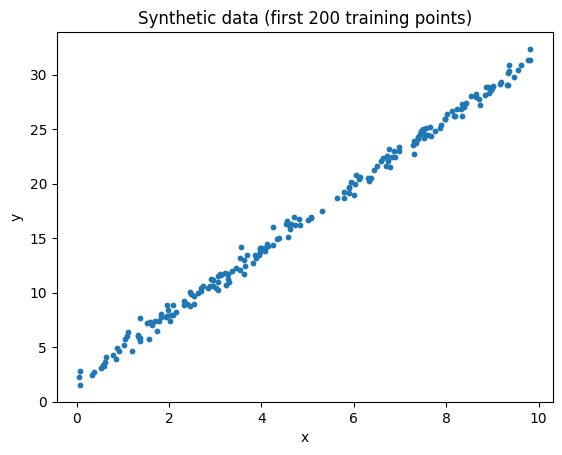

In [36]:
N = 1000
X = torch.rand(N, 1) * 10
y = 3 * X + 2 + torch.randn(N, 1) * 0.5

idx = torch.randperm(N)
X, y = X[idx], y[idx]

n_train = int(0.70 * N)
n_val = int(0.15 * N)

X_train, y_train = X[:n_train], y[:n_train]
X_val, y_val = X[n_train:n_train + n_val], y[n_train:n_train + n_val]
X_test, y_test = X[n_train + n_val:], y[n_train + n_val:]

print('train:', X_train.shape, ' val:', X_val.shape, ' test:', X_test.shape)

plt.scatter(X_train[:200], y_train[:200], s=10)
plt.title('Synthetic data (first 200 training points)')
plt.xlabel('x'); plt.ylabel('y')
plt.show()

## Task 3 (continued): Training the Model
The model is a single linear neuron (`nn.Linear(1, 1)`). Each epoch does the following:
1. **Forward pass**: predict `y` from `x`
2. **Loss**: measure the error with Mean Squared Error
3. **Backward pass**: compute gradients with backpropagation
4. **Update**: gradient descent changes the weight and bias

In [37]:
def train(lr, epochs=100):
    torch.manual_seed(0)
    model = nn.Linear(1, 1)
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    for epoch in range(epochs):
        model.train()
        pred = model(X_train)                # forward propagation
        loss = loss_fn(pred, y_train)        # loss

        optimizer.zero_grad()
        loss.backward()                      # backpropagation
        optimizer.step()                     # gradient descent step

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), y_val)

        train_losses.append(loss.item())
        val_losses.append(val_loss.item())
    return model, train_losses, val_losses

model_a, train_a, val_a = train(lr=0.01)
w, b = model_a.weight.item(), model_a.bias.item()
print(f'Learned: y = {w:.3f} * x + {b:.3f}   (true: y = 3x + 2)')
print(f'Final train loss: {train_a[-1]:.4f}, final validation loss: {val_a[-1]:.4f}')

Learned: y = 3.089 * x + 1.411   (true: y = 3x + 2)
Final train loss: 0.3167, final validation loss: 0.3321


## Task 4: Training and Validation Loss

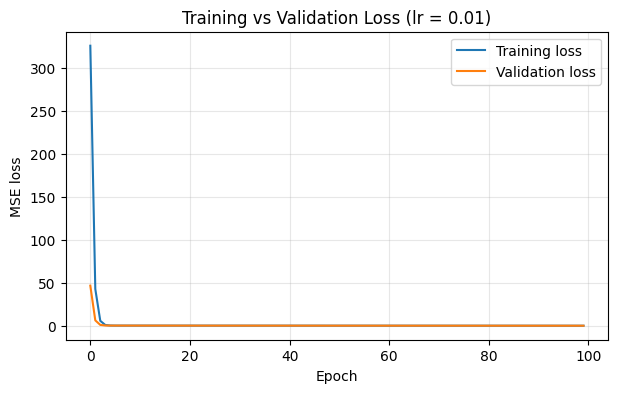

In [38]:
plt.figure(figsize=(7, 4))
plt.plot(train_a, label='Training loss')
plt.plot(val_a, label='Validation loss')
plt.title('Training vs Validation Loss (lr = 0.01)')
plt.xlabel('Epoch'); plt.ylabel('MSE loss')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig('loss_curve_assignment1.png', dpi=120, bbox_inches='tight')
plt.show()

## Task 5: Comparing Two Learning Rates

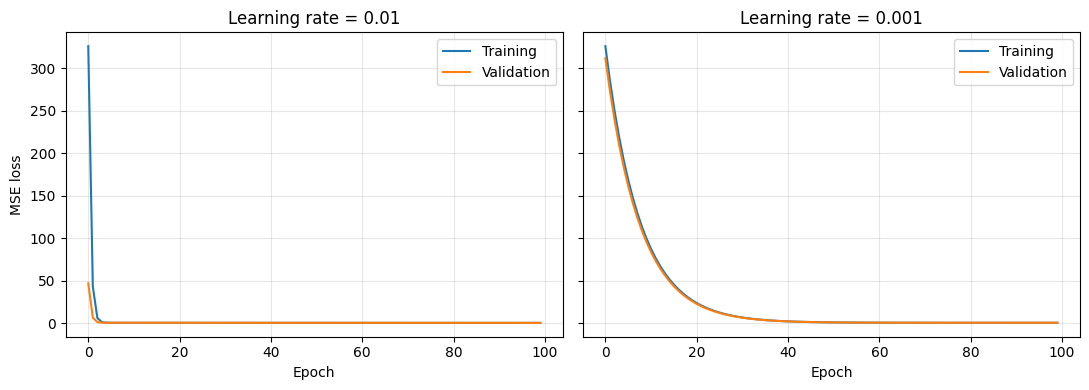

      LR |  Final train |  Final val |  weight |   bias
    0.01 |       0.3167 |     0.3321 |   3.089 |  1.411
   0.001 |       0.4484 |     0.4619 |   3.137 |  1.073


In [39]:
model_b, train_b, val_b = train(lr=0.001)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, tr, va, lr in zip(axes, [train_a, train_b], [val_a, val_b], [0.01, 0.001]):
    ax.plot(tr, label='Training')
    ax.plot(va, label='Validation')
    ax.set_title(f'Learning rate = {lr}')
    ax.set_xlabel('Epoch'); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel('MSE loss')
plt.tight_layout()
plt.savefig('lr_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'{"LR":>8} | {"Final train":>12} | {"Final val":>10} | {"weight":>7} | {"bias":>6}')
for name, m, tr, va in [(0.01, model_a, train_a, val_a), (0.001, model_b, train_b, val_b)]:
    print(f'{name:>8} | {tr[-1]:>12.4f} | {va[-1]:>10.4f} | {m.weight.item():>7.3f} | {m.bias.item():>6.3f}')

In [40]:
# Final check on the unseen test set
loss_fn = nn.MSELoss()
with torch.no_grad():
    for name, m in [('lr=0.01', model_a), ('lr=0.001', model_b)]:
        print(f'Test MSE with {name}: {loss_fn(m(X_test), y_test).item():.4f}')

Test MSE with lr=0.01: 0.3022
Test MSE with lr=0.001: 0.4147


## Conclusion
- The model learned the relationship `y = 3x + 2` from noisy data without being told the formula.
- **Learning rate 0.01** reduced the loss much faster and its learned weight and bias are close to the true values (3 and 2).
- **Learning rate 0.001** was stable but too slow: after 100 epochs it had not converged yet. It would need many more epochs.
- Training and validation loss stayed close together, so there was no overfitting.
- This shows the learning rate is one of the most important settings: too small is slow, too large can overshoot and diverge.